In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from src.config import *
RES = RES_DIR
def show(name, width=900):
    display(Image(filename=str(FIG_DIR / f"{name}.png"), width=width))


# 02 · Exploratory data analysis

Every figure below answers one question and is followed by a short interpretation. Figures are produced by `src/plots.py`
(saved in `reports/figures/`). Colours: **red = illicit, blue = licit, grey = unknown**. The train/validation/test periods are
shaded on the time-axis plots; the dashed line marks time step 43.

In [2]:
from src import plots
from src.data_loader import load_master, labelled
from src.splitting import temporal_split
master, edges = load_master()
df = labelled(master); train, val, test = temporal_split(df)
print(len(train), len(val), len(test))

24923 4971 16670


### 2.1 How imbalanced is the problem, and how much of the data can we use?

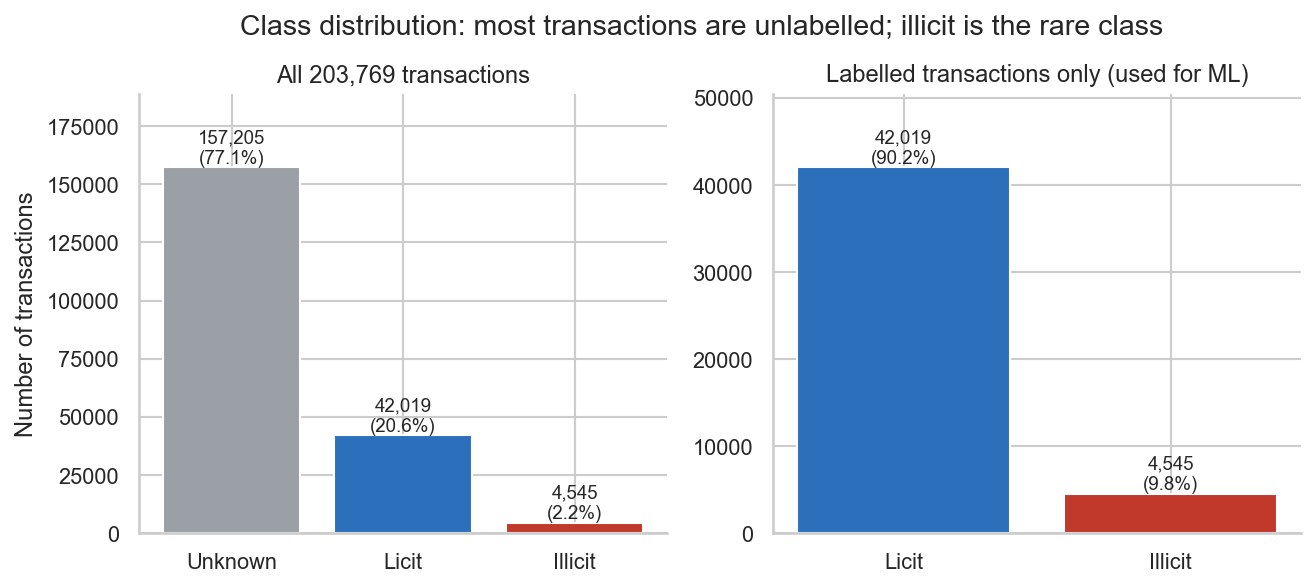

In [3]:
plots.fig_label_overview(master); show("eda_01_class_distribution")

**Insight.** 77.1% of transactions are unlabelled and unusable for supervised work; of the labelled ones only 9.8% are illicit (4,545 vs 42,019).
A classifier that always answers "licit" would score about 90% accuracy while catching no crime, so accuracy cannot be our metric; we use illicit-class precision, recall, F1 and PR-AUC.

### 2.2 How are transactions distributed over time?

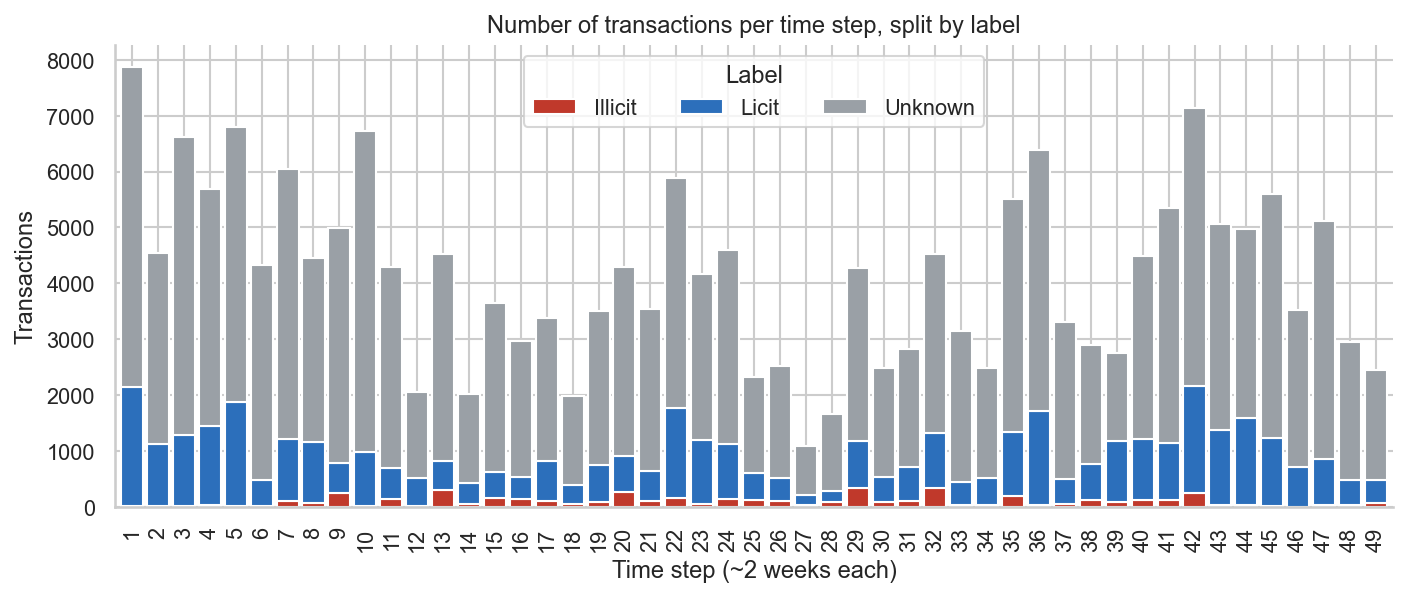

In [4]:
plots.fig_counts_per_step(master); show("eda_02_counts_per_step", 1000)

**Insight.** Steps hold between about 1,100 (step 27) and 7,900 (step 1) transactions, and roughly 78% of every step is unlabelled. The labelled sample per step is therefore small
(step 27 has only 206 labelled transactions), so per-step metrics later on rest on few cases and are noisy.

### 2.3 Does the share of illicit transactions stay constant over time? (first evidence of drift)

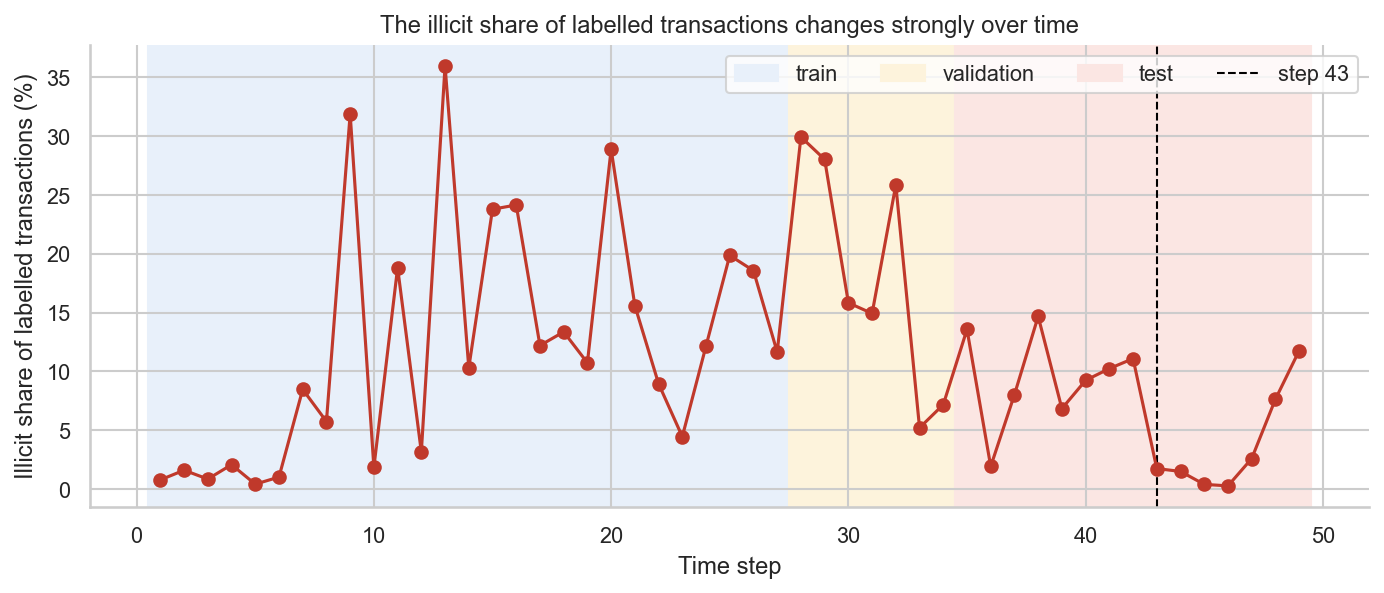

C:\Users\saish\AppData\Local\Temp\ipykernel_11844\2769659828.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rate.assign(period=pd.cut(rate.index, [0, 27, 34, 42, 49], labels=["1-27 train", "28-34 val", "35-42 test", "43-49 test"])).groupby("period", observed=True).apply(


,illicit_share,n_illicit
period,,
1-27 train,0.099,2457.0
28-34 val,0.202,1005.0
35-42 test,0.092,914.0
43-49 test,0.025,169.0


In [5]:
rate = plots.fig_illicit_rate(master); show("eda_03_illicit_rate_over_time", 1000)
rate.assign(period=pd.cut(rate.index, [0, 27, 34, 42, 49], labels=["1-27 train", "28-34 val", "35-42 test", "43-49 test"])).groupby("period", observed=True).apply(
    lambda g: pd.Series({"illicit_share": g.n_illicit.sum() / g.n_labelled.sum(), "n_illicit": g.n_illicit.sum()})).round(3)

**Insight.** The illicit share swings from 0.3% (step 46) to 36% (step 13). It averages 9.9% in the training period, **20.2% in validation**, 9.2% in steps 35-42 and then **collapses to 2.5% in steps 43-49** (only 169 illicit transactions). The base rate itself drifts,
which means a threshold tuned on the validation period (20% illicit) is tuned on an unusually illicit-rich period, and precision will change with time even if the model is unchanged. This is the first sign that the future will not look like the past.

### 2.4 Do single features separate the classes?

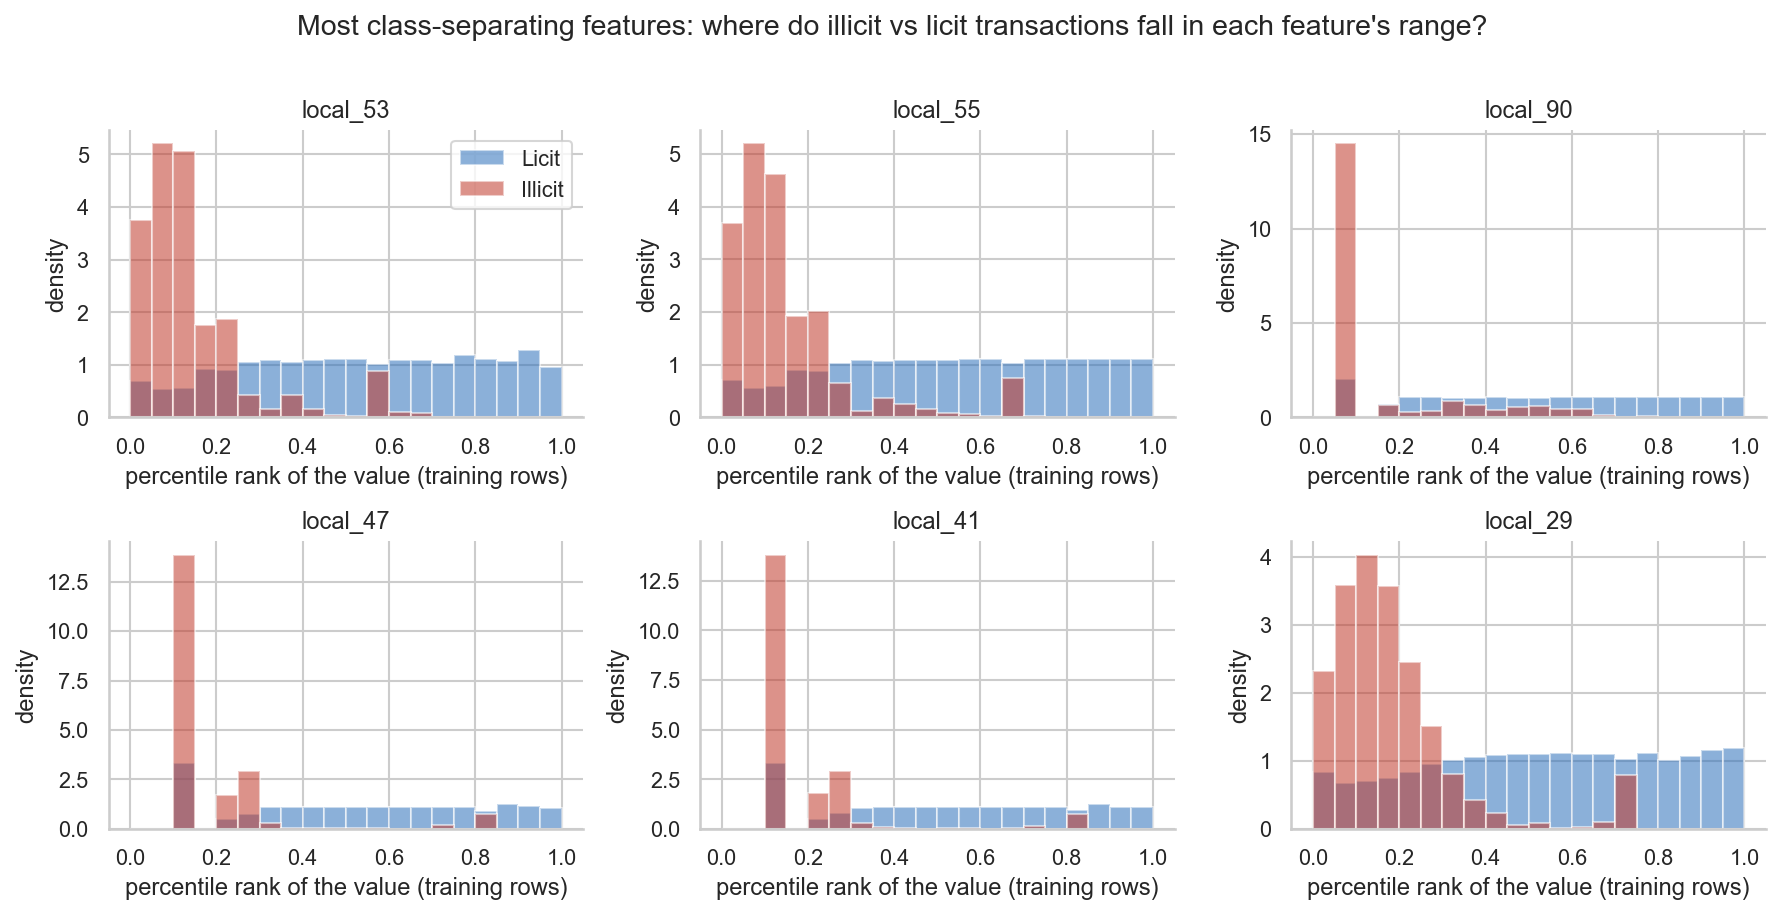

local_53    0.893
local_55    0.885
local_90    0.863
local_47    0.853
local_41    0.852
local_29    0.851
local_23    0.851
local_49    0.847
local_43    0.847
local_60    0.844
dtype: float64

In [6]:
top = plots.univariate_auc(train)          # training rows only
plots.fig_feature_distributions(train, top); show("eda_04_feature_distributions", 1000)
top.head(10).round(3)

**Insight.** Histograms use the *percentile rank* of each value because these features are spiky and heavy-tailed. For `local_53` and `local_55` illicit transactions sit in the lowest 20% of the range; for `local_90`, `local_47` and `local_41` they pile up in one low bin, whereas licit transactions are spread evenly.
Single features already reach a univariate AUC of 0.89 (`local_53`), so the classes are separable, and combinations of features should do better. Because features are anonymised we do not attach any real-world meaning to these columns.

### 2.5 Are the extreme values errors that should be removed?

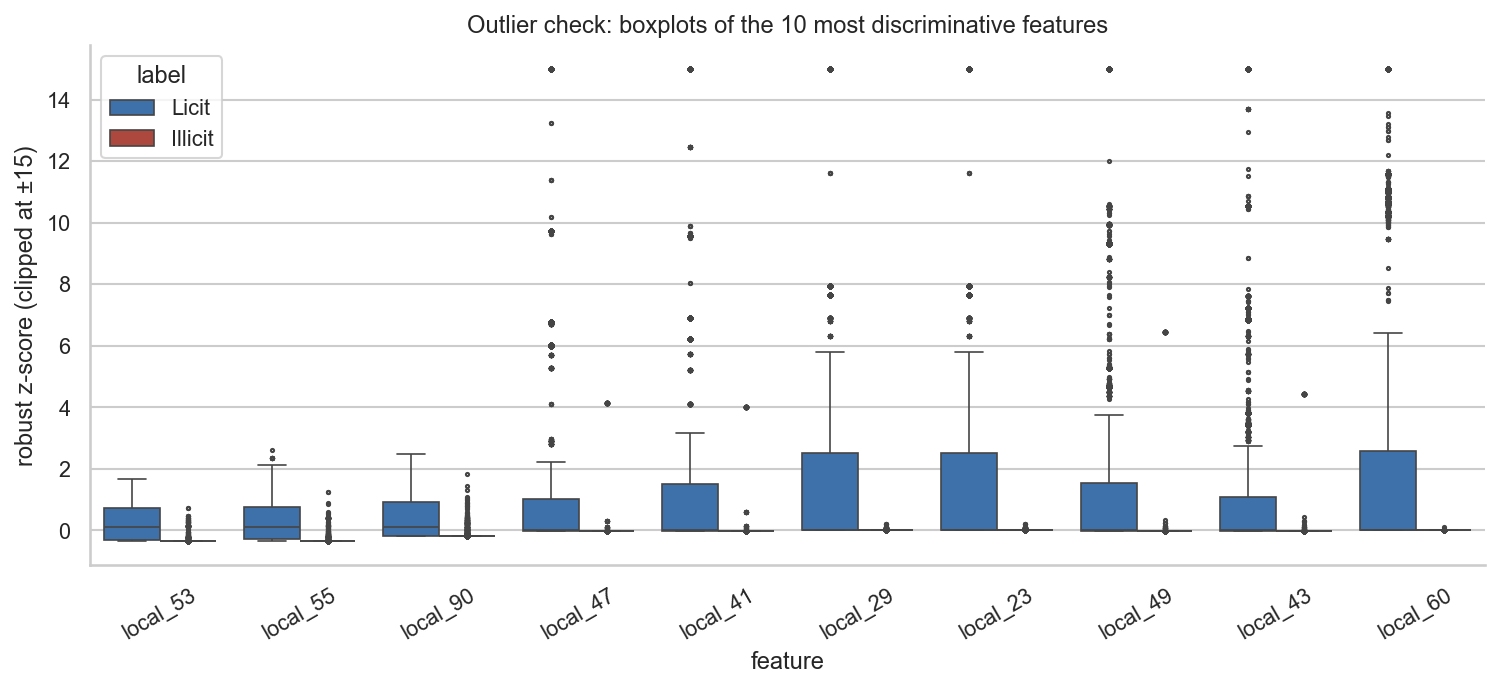

median share of values beyond 3*IQR: 0.134 | max: 0.383


In [7]:
plots.fig_boxplots(train, top); show("eda_05_boxplots_outliers")
q = json.loads((RES / "eda_stats.json").read_text())
print("median share of values beyond 3*IQR:", round(q["outlier_share_median"], 3), "| max:", round(q["outlier_share_max"], 3))

**Insight.** The long tails (robust z-scores above 10) belong almost entirely to **licit** transactions; illicit transactions occupy a narrow band near the bottom of the range. These "outliers" are therefore genuine behaviour that helps tell the classes apart, so removing them would discard signal and make the licit class look artificially uniform. We keep them.

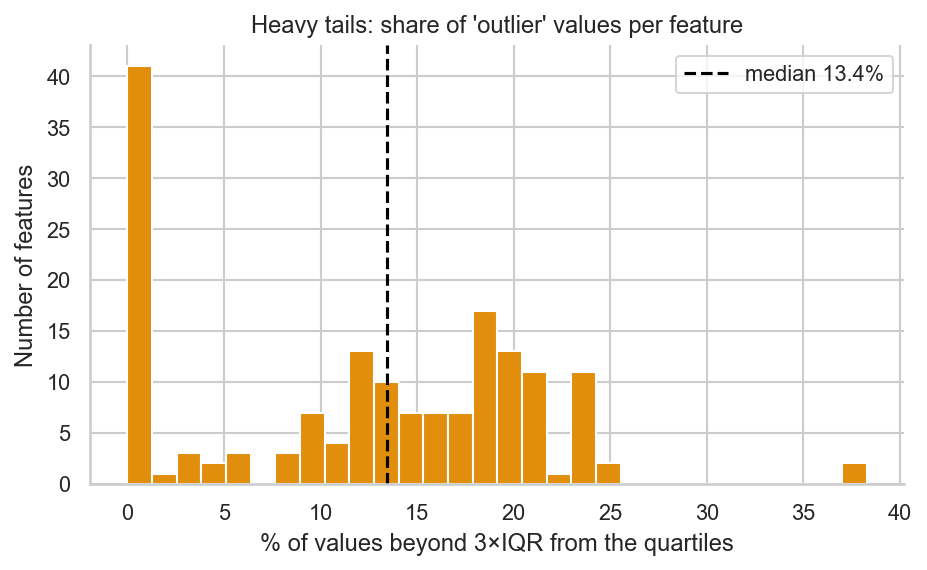

In [8]:
plots.fig_outlier_share(__import__("src.preprocessing", fromlist=["x"]).quality_report(master, edges)["outlier_share_per_feature"]); show("eda_06_outlier_share", 600)

**Insight.** The median feature has 13.4% of its values beyond 3×IQR and one has 38.3%: heavy tails are the norm, not the exception. Tree models ignore monotone rescaling so they are unaffected; Logistic Regression gets standardisation plus clipping at ±5 SD so that outliers cannot dominate.

### 2.6 Are the features redundant?

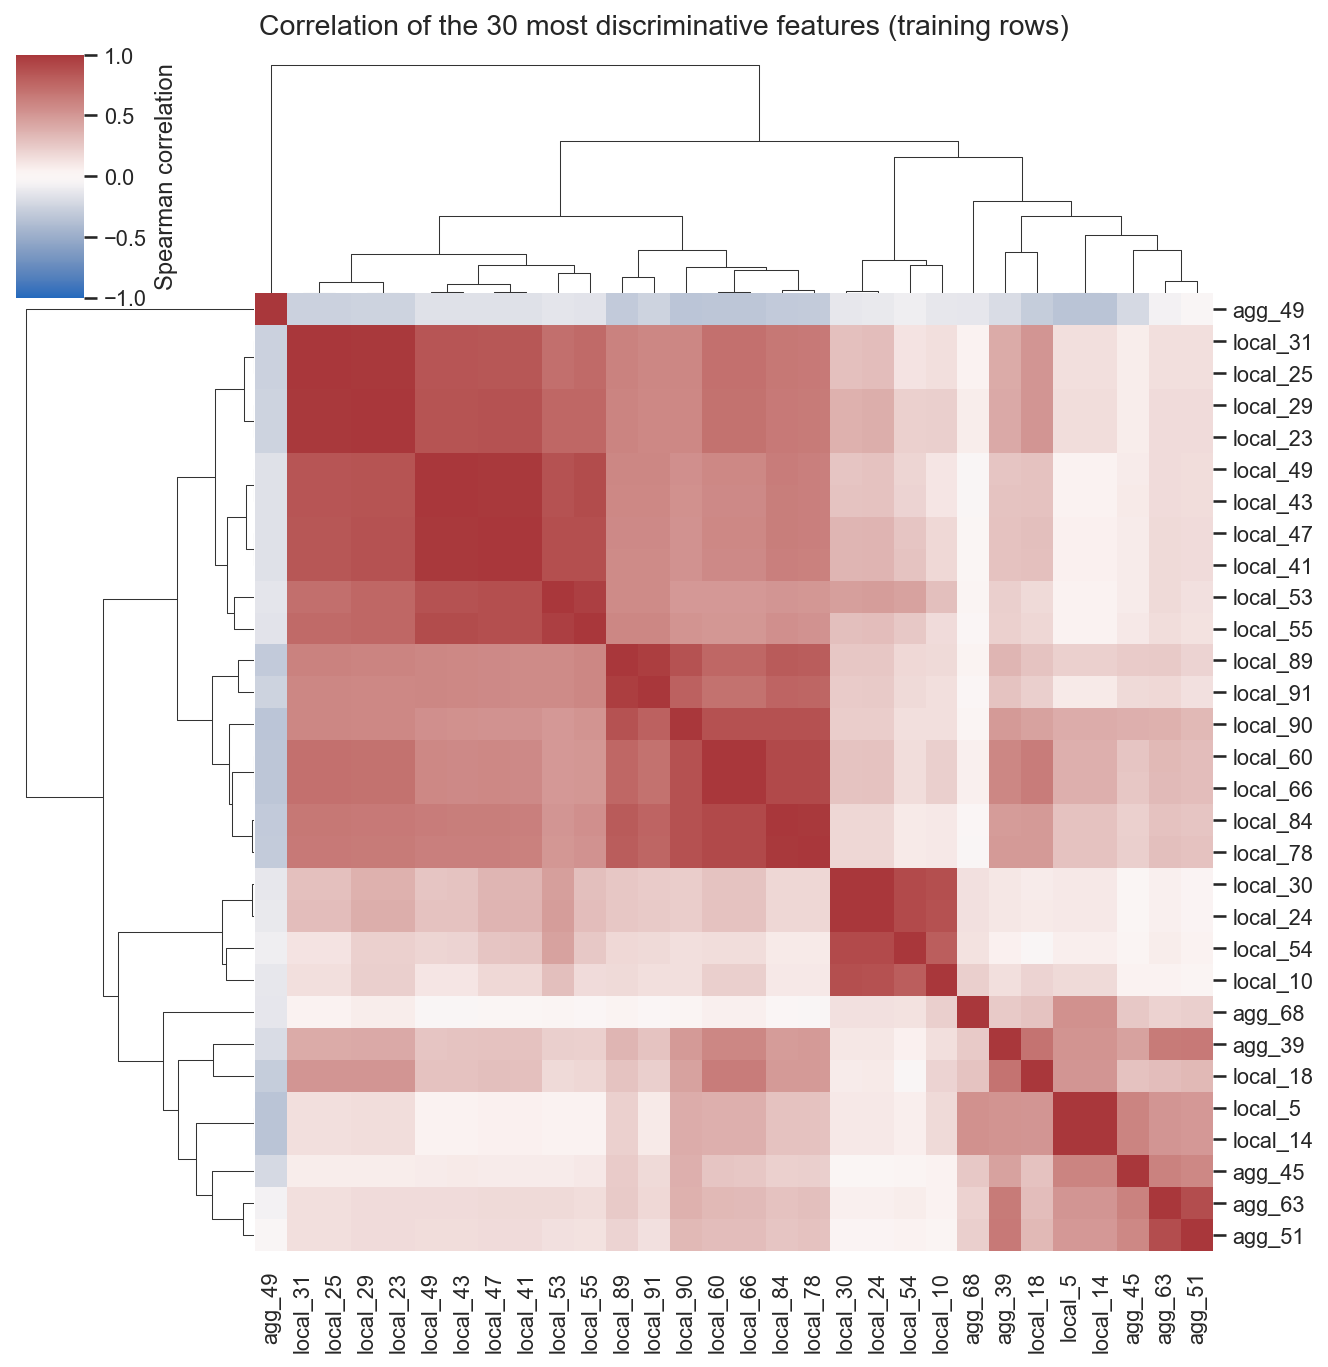

{'share_pairs_abs_corr_gt_0.9': 0.009682187730968218, 'n_pairs_gt_0.9': 131}

In [9]:
stats = plots.fig_correlation(train, top); show("eda_07_correlation", 700); stats

**Insight.** There are clear blocks of near-duplicate local features (for example `local_23/25/29/31` and `local_41/43/47/49`). Across all 165 features 131 of 13,530 pairs (1.0%) have |Spearman ρ| above 0.9, so redundancy is real but limited. Consequence for interpretation: when features are correlated, a model can spread importance among them, so individual importances should be read as indicative, not exact.

### 2.7 How big are the class differences?

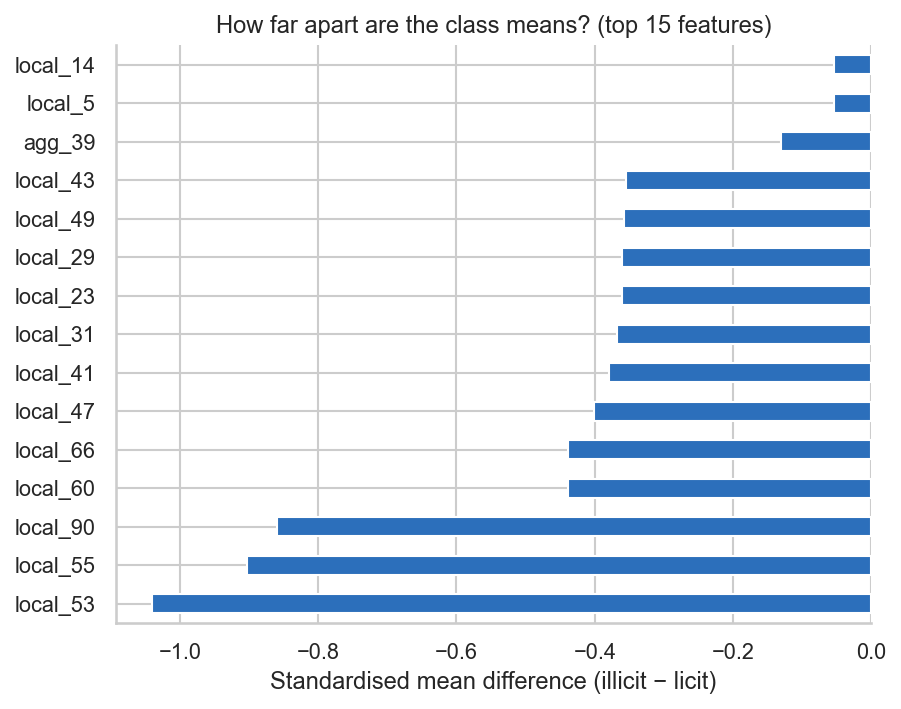

local_53   -1.04
local_55   -0.90
local_90   -0.86
local_47   -0.40
local_41   -0.38
dtype: float32

In [10]:
d = plots.fig_effect_sizes(train, top); show("eda_08_effect_sizes", 600); d.round(2).head(5)

**Insight.** Illicit transactions have *lower* values on all of the 15 most discriminative features. The largest standardised mean difference is only about one standard deviation (`local_53`: -1.04, `local_55`: -0.90, `local_90`: -0.86); no single feature is decisive, which is why multi-feature models are needed.

### 2.8 Do the input distributions change over time?

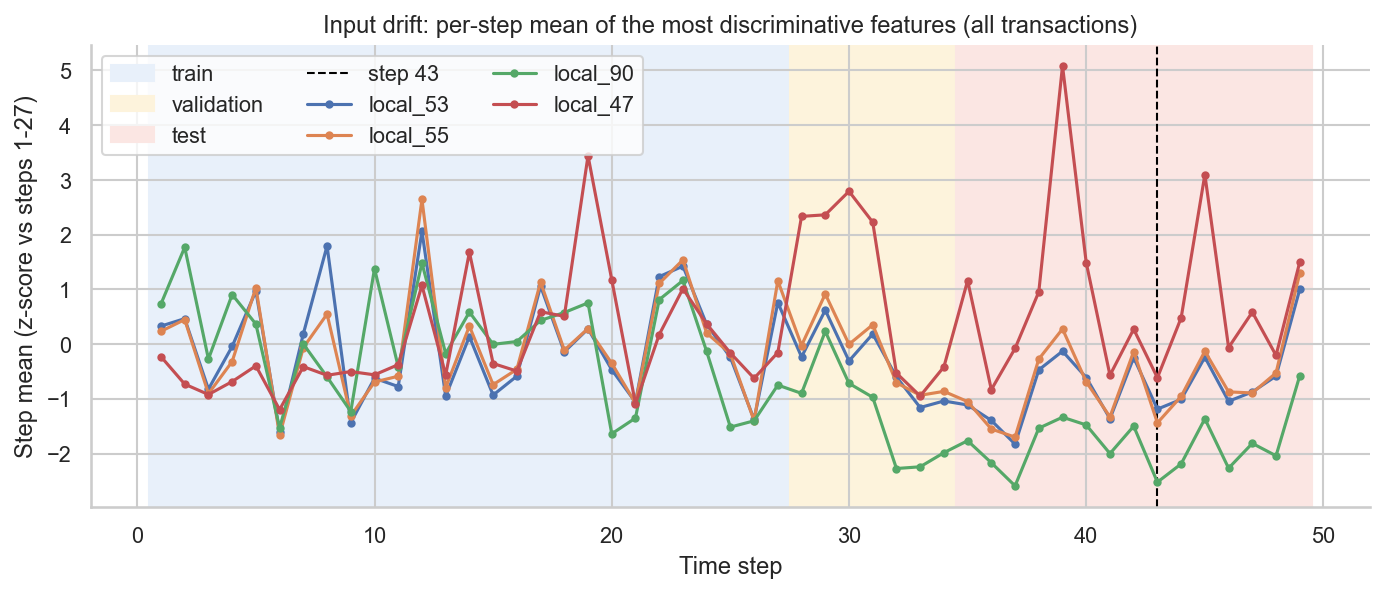

In [11]:
plots.fig_feature_drift_means(master, top); show("eda_09_feature_mean_drift", 1000)

**Insight.** The per-step average of the most discriminative features mostly stays within about ±2 SD of its training level during steps 1-27 (with occasional spikes, e.g. `local_47` at step 19), but then moves persistently away: `local_90` sits roughly 2 SD *below* its training level from step ~32 onward, and `local_47` has large spikes in the test period. The inputs are shifting even before step 43.

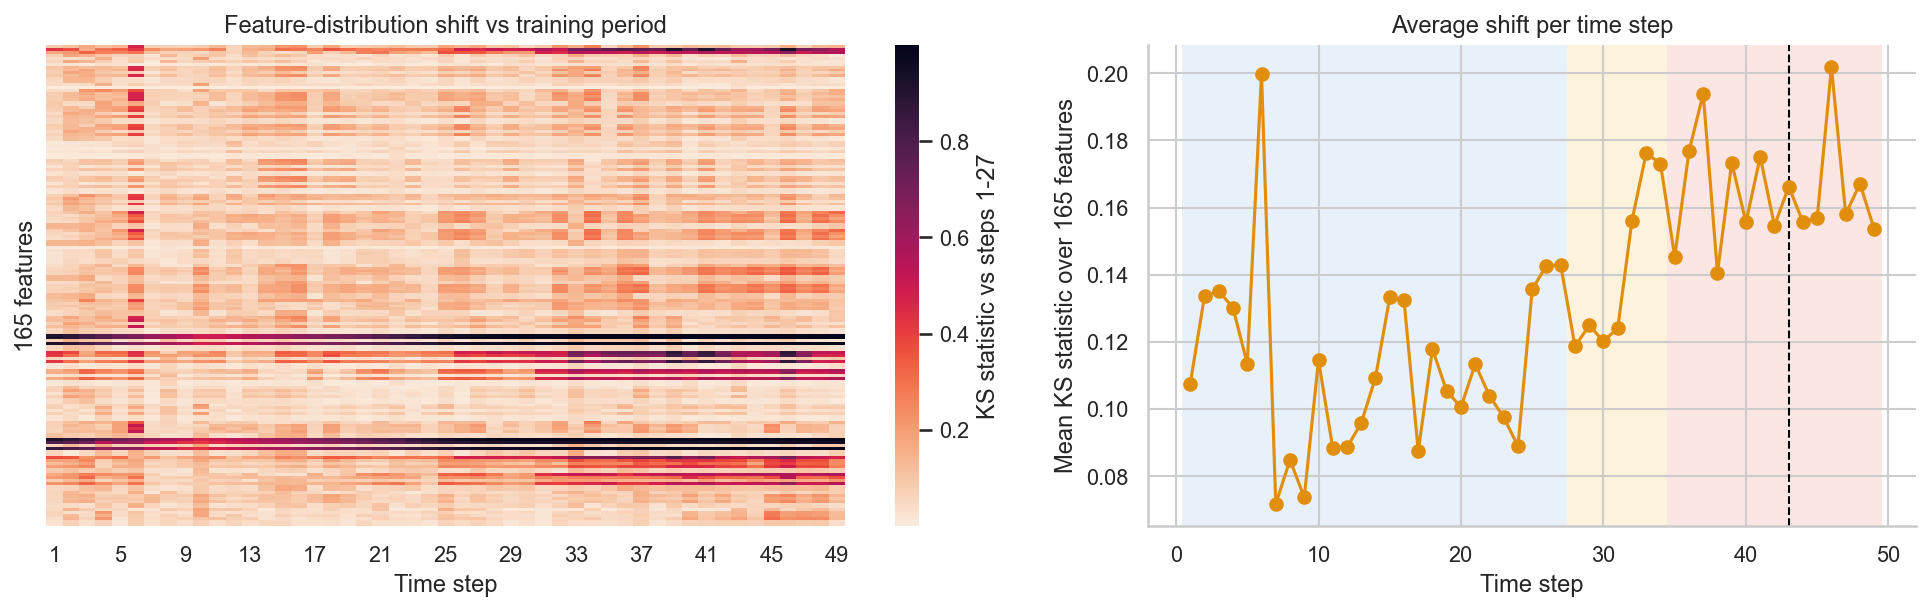

,mean KS,share of features with KS>0.2
1-27,0.113,0.110
28-34,0.142,0.165
35-42,0.164,0.192
43-49,0.166,0.213


In [12]:
ks = pd.read_csv(RES / "feature_drift_ks.csv", index_col=0)
plots.fig_ks_heatmap(ks); show("eda_10_feature_drift_ks", 1100)
m = ks.mean(axis=1)
pd.DataFrame({p: {"mean KS": m.loc[a:b].mean(), "share of features with KS>0.2": (ks.loc[a:b] > 0.2).mean().mean()}
              for p, (a, b) in {"1-27": (1, 27), "28-34": (28, 34), "35-42": (35, 42), "43-49": (43, 49)}.items()}).T.round(3)

**Insight.** Measured with the Kolmogorov-Smirnov statistic against the training period (all 203,769 transactions, no labels needed), average feature shift rises steadily from 0.113 (steps 1-27) to 0.142 (28-34), 0.164 (35-42) and 0.166 (43-49); the share of features with KS above 0.2 doubles from 11% to 21%.
The drift in the inputs is **gradual** and does not jump at step 43. Since performance collapses abruptly after step 43 (notebook 05), this suggests that the main problem is a change in *how the features relate to the label* (concept drift), not only a shift in the feature values.

## Summary of EDA findings
1. Strong class imbalance (9.8% illicit among labelled) and 77% unlabelled data.
2. The illicit share is not constant (0.3% to 36%) and falls to 2.5% after step 43.
3. Heavy-tailed, partly redundant features; extremes are informative so outliers are kept.
4. Individual features separate the classes only moderately (AUC up to 0.89), so we need multivariate models.
5. Input distributions drift gradually; the label relationship appears to change sharply later.